# Aim: Detect the single flowing capsules passing through the funnel region of the millifluidic device and compute the slope of its trajectory.
            Fit the contours and get the shpae and compute centroid (cx, cy), displacement (dx, dy) and area
            compute velocity vectors and angle of the centroid subtended on reference point with horizontal axis
            Fit a straight line constrained to pass through a reference point and to the centroid points of the detected streaks
            Compute the slope of the fitted line, which will represent the angle of the flowing capsule's trajectory

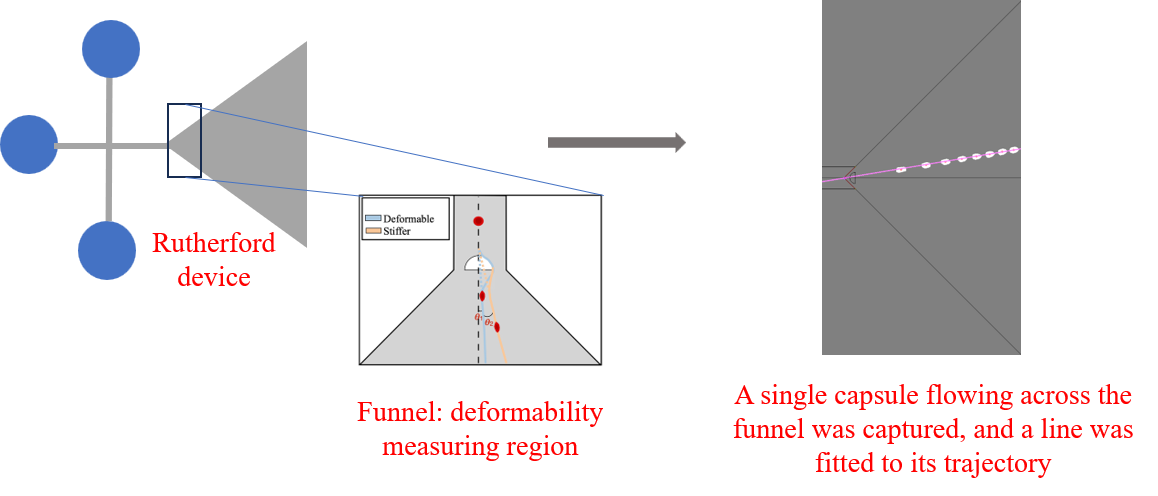

    Import usefull libraries

In [1]:
import cv2
import os
import json
import numpy as np
import pandas as pd
from scipy import ndimage
import glob
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt

### Edit the recorded video

    -Inspect: Watch the raw video to identify frame segments where flow focusing is stable and free from bubbles or device movement
    -Trim: trim the videos save it from where the flow is estabilished and ostacle is clearly visible
    -Rotate: Align the channel orientation approximate horizontally to match the target reference frame as shown below
    -Crop: crop the video to avoid the detection of beads/capsules in main channel before striking to the obstacle

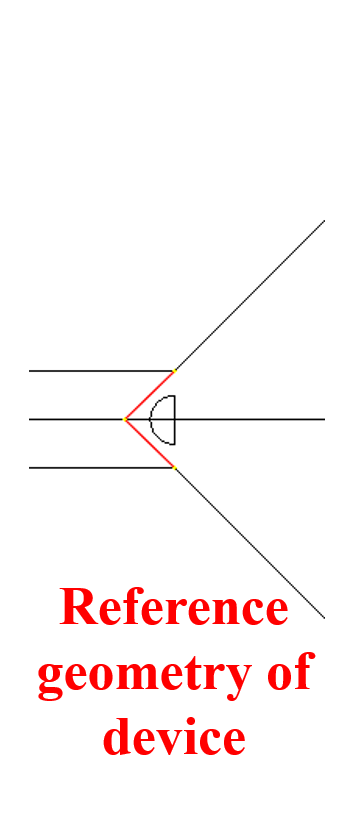

This video editor tab will apear when you run the below cell

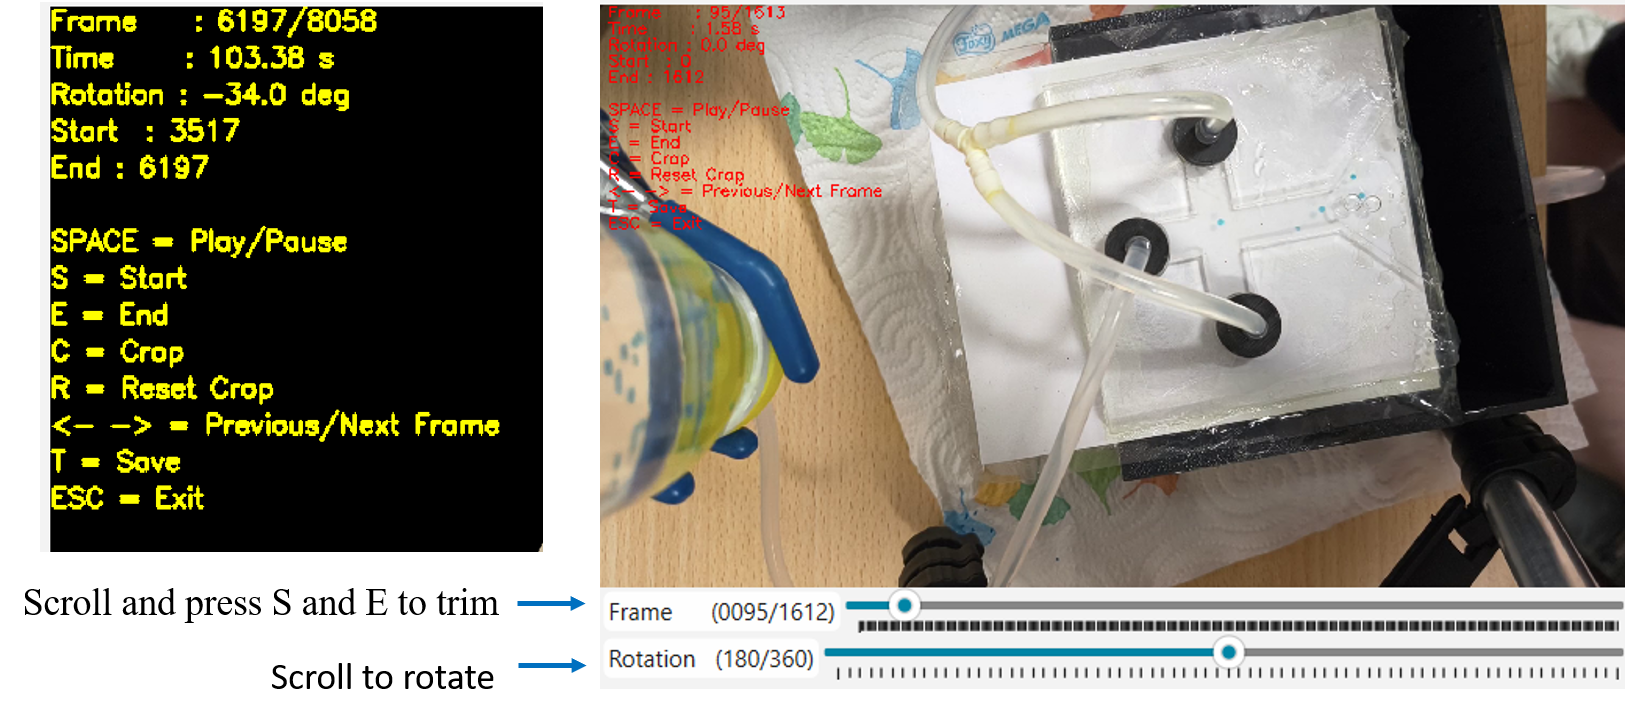

    Rotate and crop the video like shown in the image below, and while trimming start the video by pressing S when the obstacle and device edges apears clear.

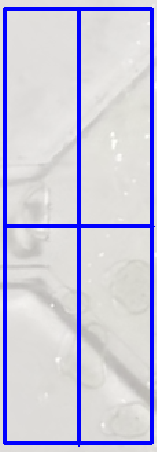

In [5]:

# Give the video path and edit the video

# video_path = r
video_path = r"Z:\Healthy_Storage_Data\Healthy_subject 3\Day54-11-09-2025\Day54-donor3-40X-2025-09-11-13-46-47_2.mov"
# video_path = r"E:\ICTP\Hands-on_Day10\11cm_14-08.mp4"

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

current_frame = 0
playing = False
start_frame = 0
end_frame = total_frames - 1
crop_roi = None
window_name = "Video Editor"
cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
def nothing(x):
    pass

def rotate_image(image, angle):
    h, w = image.shape[:2]
    center = (w // 2, h // 2)
    M = cv2.getRotationMatrix2D(center, angle, 1.0)

    cos = abs(M[0, 0])
    sin = abs(M[0, 1])

    new_w = int(h * sin + w * cos)
    new_h = int(h * cos + w * sin)

    M[0, 2] += (new_w / 2) - center[0]
    M[1, 2] += (new_h / 2) - center[1]

    rotated = cv2.warpAffine(image, M, (new_w, new_h), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0))

    return rotated
cv2.createTrackbar("Frame", window_name, 0, total_frames - 1, nothing)
cv2.createTrackbar("Rotation", window_name, 180, 360, nothing)

while True:
    rotation_angle = cv2.getTrackbarPos("Rotation", window_name) - 180
    if playing:
        current_frame += 1
        if current_frame >= total_frames:
            current_frame = total_frames - 1
            playing = False
        cv2.setTrackbarPos("Frame", window_name, current_frame)

    else:
        current_frame = cv2.getTrackbarPos("Frame", window_name)
    cap.set(cv2.CAP_PROP_POS_FRAMES, current_frame)
    ret, frame = cap.read()
    if not ret:
        break

    rotated_frame = rotate_image(frame, rotation_angle)
    display = rotated_frame.copy()
    if crop_roi is not None:
        x, y, w, h = crop_roi
        cv2.rectangle(display, (x, y), (x + w, y + h), (0, 255, 0), 2)

    info = [ f"Frame    : {current_frame}/{total_frames}",  f"Time     : {current_frame / fps:.2f} s", f"Rotation : {rotation_angle:.1f} deg", f"Start  : {start_frame}", f"End : {end_frame}",
        "",  "SPACE = Play/Pause", "S = Start", "E = End", "C = Crop", "R = Reset Crop", "<- -> = Previous/Next Frame", "T = Save", "ESC = Exit",]

    y0 = 25
    for line in info:
        cv2.putText(display, line, (15, y0), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2, )
        y0 += 30

    cv2.imshow(window_name, display)
    key = cv2.waitKey(30) & 0xFF
    if key == 27:
        break
    elif key == ord(" "):
        playing = not playing
    elif key == ord("s"):
        start_frame = current_frame
        print("Start =", start_frame)
    elif key == ord("e"):
        end_frame = current_frame
        print("End =", end_frame)
    elif key == ord("c"):
        playing = False
        roi = cv2.selectROI(window_name, rotated_frame, showCrosshair=True, fromCenter=False,)
        if roi[2] > 0 and roi[3] > 0:
            crop_roi = roi
    elif key == ord("r"):
        crop_roi = None
    elif key == ord("a"):
        current_frame = max(0, current_frame - 10)
        cv2.setTrackbarPos("Frame", window_name, current_frame)
    elif key == ord("d"):
        current_frame = min(total_frames - 1, current_frame + 10)
        cv2.setTrackbarPos("Frame", window_name, current_frame)
    elif key == 81:  
        current_frame = max(0, current_frame - 1)
        cv2.setTrackbarPos("Frame", window_name, current_frame)
    elif key == 83:   
        current_frame = min(total_frames - 1, current_frame + 1)
        cv2.setTrackbarPos("Frame", window_name, current_frame)

    elif key == ord("t"):
        print("Saving...")
        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

        first_ret, first_frame = cap.read()
        if not first_ret:
            continue

        first_rotated = rotate_image(first_frame, rotation_angle)
        if crop_roi is None:
            out_h, out_w = first_rotated.shape[:2]
        else:
            # x, y, w, h = crop_roi
            out_w = w
            out_h = h

        cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)
        output_name = (
            os.path.splitext(video_path)[0]
            + "_edited.mp4"
        )

        writer = cv2.VideoWriter(
            output_name,
            cv2.VideoWriter_fourcc(*"mp4v"),
            fps,
            (out_w, out_h),
        )
        for f in range(start_frame, end_frame + 1):
            ret, img = cap.read()
            if not ret:
                break
            img = rotate_image(img, rotation_angle)
            if crop_roi is not None:
                img = img[y:y + h, x:x + w]

            writer.write(img)
        writer.release()
        print("Saved to:")
        print(output_name)


cap.release()
cv2.destroyAllWindows()

Start = 1123
End = 1526
Saving...
Saved to:
Z:\Healthy_Storage_Data\Healthy_subject 3\Day54-11-09-2025\Day54-donor3-40X-2025-09-11-13-46-47_2_edited.mp4


    After editing the videos save them into the base folder as shown

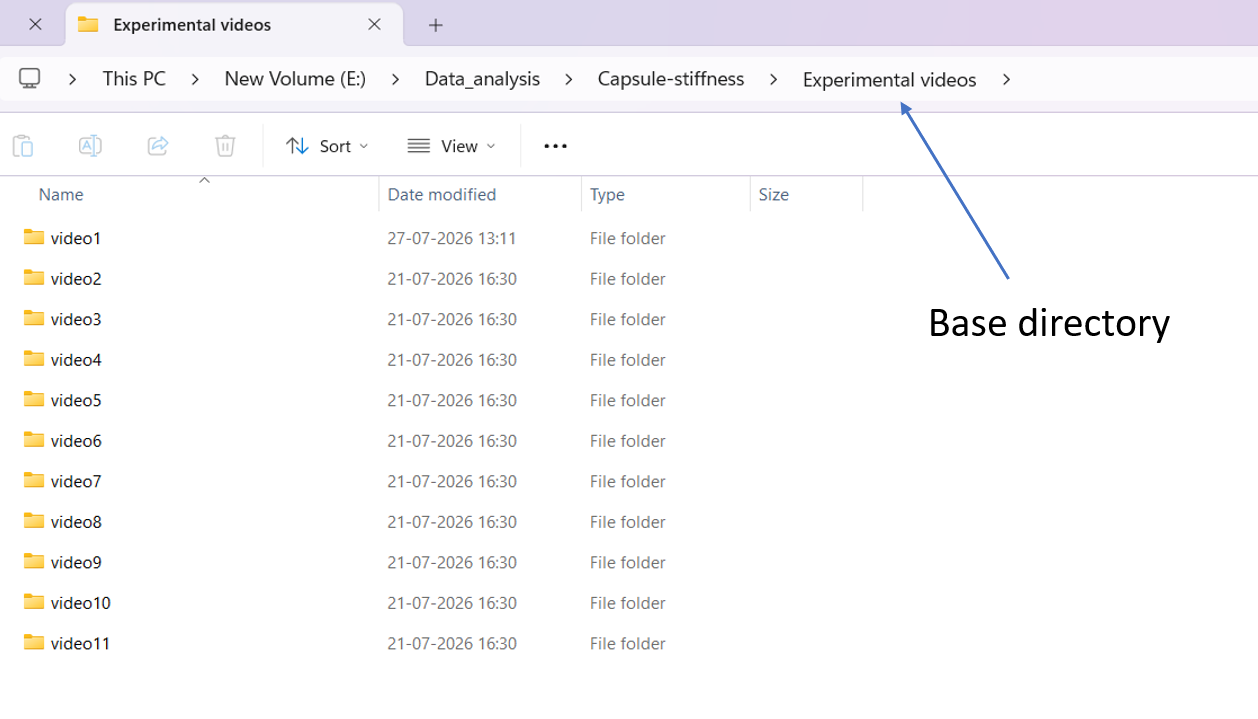

## Align the edited videos and generate the alignment factors for analysis

#### Align the first frame of the edited video with the reference geometry of device to generate alignment factors in JASON file
     To run the below cell, set the directory you will see the separate terminal cv2 window in Taskbar* for alignment
     You have to align the first frame of the  video over the reference geometry of the device (CAD design)
     The instructions will appear on the generated window
     specific key is assigned for the specific operations please read

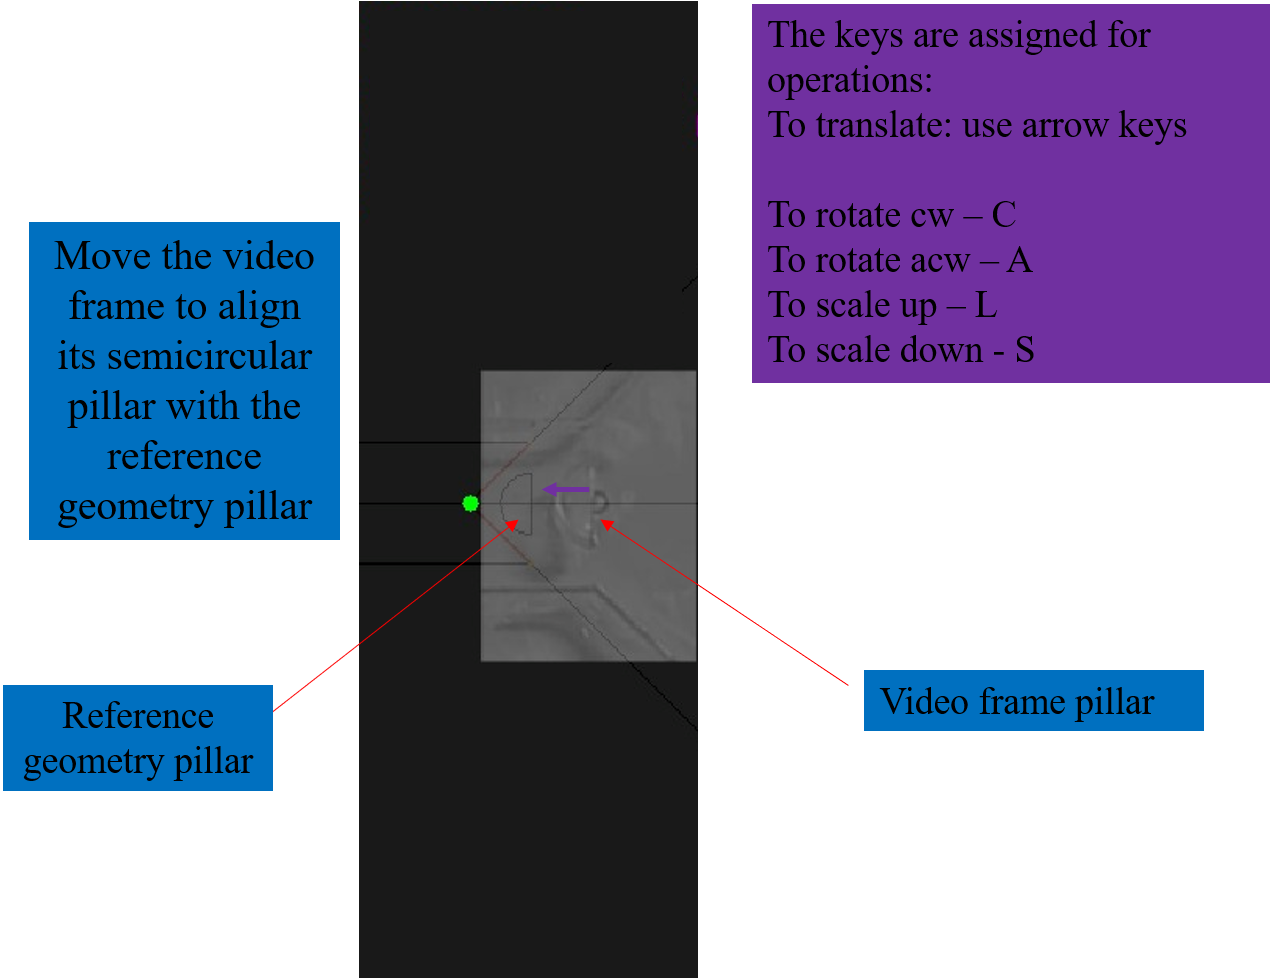

In [ ]:
# video_path = r
# video_path = r
# video_path = r
video_path = r"E:\ICTP\Hands-on_Day10\video4\11cm-14-08_edited.mp4"

# reference_image = r
reference_image = r"E:\Data_analysis\Capsule-stiffness\ref_image_capsule_device.png"

# output_folder = r
# output_folder = r
output_folder = r"E:\ICTP\Hands-on_Day10\video4"

    
os.makedirs(output_folder, exist_ok=True)

json_file = os.path.join(output_folder, "alignment_parameters.json")


cap = cv2.VideoCapture(video_path)

ret, frame = cap.read()

frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
video_h, video_w = frame_gray.shape

ref_color = cv2.imread(reference_image)
ref_gray = cv2.cvtColor(ref_color, cv2.COLOR_BGR2GRAY)
ref_h, ref_w = ref_gray.shape

def mouse_event_handler(event, x, y, flags, param):
    global tx, ty, drag, x0, y0, ref_point
    if event == cv2.EVENT_LBUTTONDOWN:
        if flags & cv2.EVENT_FLAG_CTRLKEY:
            ref_point = (x, y)
            print(f"Reference Point : {ref_point}")
        else:
            drag = True
            x0, y0 = x, y
    elif event == cv2.EVENT_MOUSEMOVE and drag:
        tx += x - x0
        ty += y - y0
        x0, y0 = x, y
    elif event == cv2.EVENT_LBUTTONUP:
        drag = False

def generate_overlay():
    center = (video_w // 2, video_h // 2)
    R = cv2.getRotationMatrix2D(center, angle, scale)
    img = cv2.warpAffine(
        frame_gray,
        R,
        (video_w, video_h),
        flags=cv2.INTER_LINEAR)

    T = np.float32([[1, 0, tx], [0, 1, ty]])
    img = cv2.warpAffine(img, T, (ref_w, ref_h), flags=cv2.INTER_LINEAR)
    img = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

    overlay = cv2.addWeighted(ref_color, 0.1, img, 0.4, 0.1)
    if ref_point is not None:
        cv2.circle(overlay, ref_point, 4, (0,255,0), -1)
    cv2.putText(overlay,"Drag : Mouse",(10,30),
                cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,255),1)
    cv2.putText(overlay,"Move in X: use arrow",(10,60),
                cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,255),1)
    cv2.putText(overlay,"Move in Y:  - ",(10,80),
                cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,255),1)
    cv2.putText(overlay,"A (acw) and C(cc)",(10,100),
                cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,255),1)
    cv2.putText(overlay,"Scale : L & S",(10,120),
                cv2.FONT_HERSHEY_SIMPLEX,0.5,(255,0,255),1)
    cv2.putText(overlay,"CTRL + Left Click : Select Reference Point",
                (10,650),
                cv2.FONT_HERSHEY_SIMPLEX,0.65,(0,0,0),2)
    cv2.putText(overlay,"ENTER : Save Alignment",
                (10,690),
                cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,0,0),2)
    return overlay
def load_alignment(json_path):
    with open(json_path,"r") as f:
        d = json.load(f)
    return (d["translation_x"], d["translation_y"], d["rotation_angle"], d["scaling_factor"], tuple(d["reference_coordinate"]) if d["reference_coordinate"] else None)
def save_alignment(json_path):
    data = {"translation_x": tx, "translation_y": ty, "rotation_angle": angle, "scaling_factor": scale, "reference_coordinate": ref_point}
    with open(json_path,"w") as f:
        json.dump(data,f,indent=4)
    print("Alignment saved.")

tx = ty = 0
angle = 0
scale = 1.0
drag = False
x0 = y0 = 0

ref_point = None
USE_SAVED = True

if USE_SAVED and os.path.exists(json_file):
    tx, ty, angle, scale, ref_point = load_alignment(json_file)

cv2.namedWindow("Alignment", cv2.WINDOW_NORMAL)
cv2.resizeWindow("Alignment",600,900)
cv2.setMouseCallback("Alignment", mouse_event_handler)
while True:
    cv2.imshow("Alignment", generate_overlay())
    k = cv2.waitKey(20) & 0xFF
    if k == 37:          
        tx -= 2

    elif k == 39:        
        tx += 2

    elif k == 38:        
        ty -= 2

    elif k == 40:       
        ty += 2
        ty += 2
    elif k == 99:
        angle -= 0.3
    elif k == 97:
        angle += 0.3
    elif k == 108:
        scale += 0.02
    elif k == 115:
        scale -= 0.02
    elif k == 13:      
        break
    elif k == 27:      
        exit()
        
cv2.destroyAllWindows()
save_alignment(json_file)
print(f"Translation : ({tx:.1f}, {ty:.1f})")
print(f"Rotation    : {angle:.2f}")
print(f"Scale       : {scale:.3f}")
print(f"Reference   : {ref_point}")

Alignment saved.
Translation : (61.0, 103.0)
Rotation    : 0.00
Scale       : 0.880
Reference   : (63, 271)


    Video folders should contain the video and alignment file as shown to start the analysis

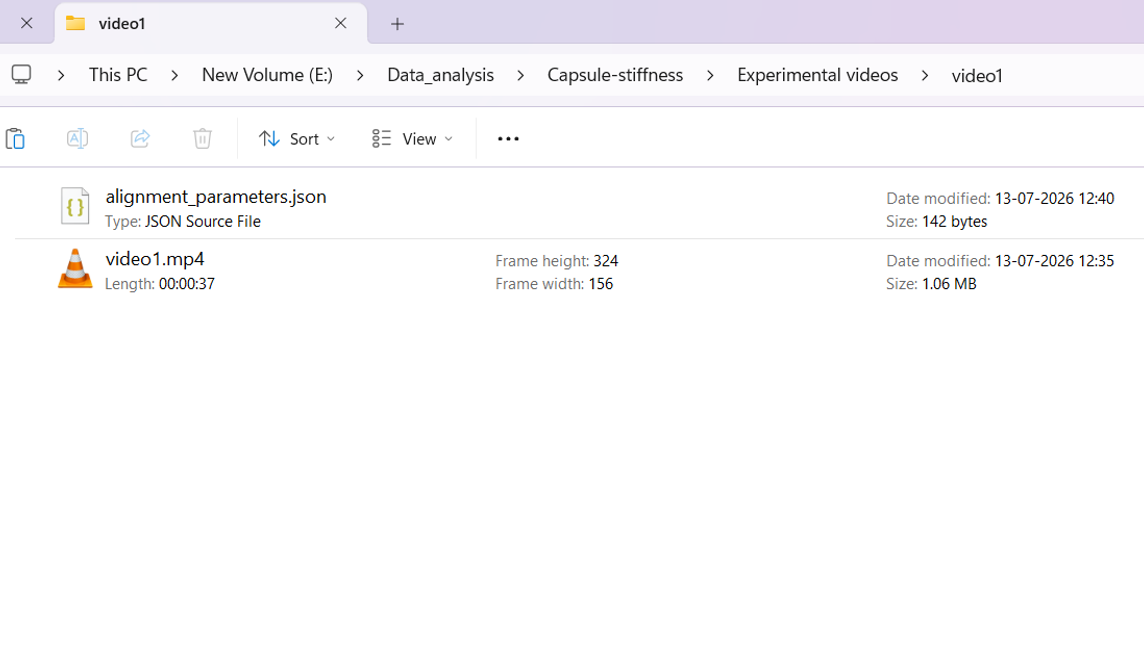

## Compute the angle and velocities of the beads flowing through the funnel

In [ ]:
reference_image_path = r"E:\Data_analysis\Capsule-stiffness\ref_image_capsule_device.png"

# base_results_dir = rx
base_results_dir = r"E:\ICTP\Hands-on_Day10"
# base_results_dir = r"E:\ICTP\Hands-on_Day9"

def load_alignment_parameters(alignment_file_path):
    if not os.path.exists(alignment_file_path):
        raise FileNotFoundError("Alignment file not found... first run alignment")
    with open(alignment_file_path, "r") as f:
        data = json.load(f)
    return (data["translation_x"], data["translation_y"], data["rotation_angle"], data["scaling_factor"],
        tuple(data["reference_coordinate"]) if data.get("reference_coordinate") else None)

def img_processing(subtracted_frame, median_kernel_size=5, structuring_radius=5, min_area=100, max_area=500):
    binary_map = (subtracted_frame).astype(np.uint8) * 255
    if median_kernel_size:
        binary_map = cv2.medianBlur(binary_map, median_kernel_size)
    binary_map = (ndimage.binary_fill_holes(binary_map > 0).astype(np.uint8) * 255)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2*structuring_radius, structuring_radius))
    binary_map = cv2.morphologyEx(binary_map, cv2.MORPH_OPEN, kernel)
    binary_map = cv2.morphologyEx(binary_map, cv2.MORPH_CLOSE, kernel)
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(binary_map, connectivity=8)
    filtered = np.zeros_like(binary_map)
    valid_count = 0
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if min_area <= area <= max_area:
            filtered[labels == i] = 255
            valid_count += 1
    return filtered, valid_count

def save_as_uint8(image, file_path):
    os.makedirs(os.path.dirname(file_path) or ".", exist_ok=True)
    if image.dtype != np.uint8:
        image = (np.clip(image, 0, 1) * 255).astype(np.uint8)
    cv2.imwrite(file_path, image)

def save_block_images(objects, save_dir, label):
    combined = None
    for _, obj in objects:
        combined = obj if combined is None else cv2.bitwise_or(combined, obj)
    if combined is not None:
        cv2.imwrite(os.path.join(save_dir, f"{label}.png"), combined)

def process_cell(block, cell_index, output_directory, objects_directory, reference_coordinate,
                 summary_txt_path, false_positive_dir, diff_cells_dir, invalid_dir, centroid_velocity):
    if len(block) == 0:
        return cell_index

    centroids = []
    objects = []
    for r in block:
        if pd.isna(r['centroid_x']) or pd.isna(r['centroid_y']):
            continue
        frame_id = r['frame_index']
        obj_path = os.path.join(objects_directory, f"Object_{frame_id}.png") 
        obj = cv2.imread(obj_path, cv2.IMREAD_GRAYSCALE)
        if obj is None:
            continue
        objects.append((frame_id, obj))
        centroids.append((r['centroid_x'], r['centroid_y'], frame_id))

    if len(centroids) == 0 or len(objects) == 0:
        return cell_index

    rx, ry = reference_coordinate

    for i in range(1, len(centroids)):
        if centroids[i][0] < centroids[i-1][0]:
            print(f"Frames {centroids[0][2]}-{centroids[-1][2]}: DIFFERENT CELLS")
            save_block_images(objects, diff_cells_dir, f"frame_{centroids[0][2]}_{centroids[-1][2]}")
            return cell_index

    xs = np.array([c[0] for c in centroids])
    ys = np.array([c[1] for c in centroids])
    dx = xs - rx
    dy = ys - ry
    denom = np.sum(dx**2)
    if denom == 0:
        print("invalid object")
        return cell_index

    slope = np.sum(dx * dy) / denom
    angle_ls = np.arctan(slope)
    abs_angle_ls = abs(angle_ls)

    theta_points = np.arctan2(dy, dx)
    delta_theta = np.arctan2(np.sin(theta_points - angle_ls), np.cos(theta_points - angle_ls))
    ls_mse = np.sqrt(np.mean(delta_theta**2))
    ls_me = np.mean(delta_theta)

    if abs_angle_ls >= 0.76:
        print(f"Frames {centroids[0][2]}-{centroids[-1][2]}: angle > 45°")
        save_block_images(objects, invalid_dir, f"invalid_{centroids[0][2]}_{centroids[-1][2]}")
        return cell_index

    # False positive filter
    filtered_centroids = []
    for cx, cy, frame_id in centroids:
        if abs(cx - rx) < 20:
            print(f"Frame {frame_id}: false positive")
            obj = cv2.imread(os.path.join(objects_directory, f"Object_{frame_id}.png"), cv2.IMREAD_GRAYSCALE)
            if obj is not None:
                cv2.imwrite(os.path.join(false_positive_dir, f"frame_{frame_id}.png"), obj)
            continue
        filtered_centroids.append((cx, cy, frame_id))
    if len(filtered_centroids) == 0:
        return cell_index
    centroids = filtered_centroids


    start_f = centroids[0][2]
    end_f = centroids[-1][2]
    n_frames = len(centroids)



    # Valid cell
    cell_index += 1
    cell_folder = os.path.join(output_directory, "detacted_capsule", f"cell_{cell_index}_{start_f}_{end_f}")
    os.makedirs(cell_folder, exist_ok=True)

    combined_object = None
    for indx, obj in objects:
        combined_object = obj if combined_object is None else cv2.bitwise_or(combined_object, obj)
        # cv2.imwrite(os.path.join(consecutive_centroids1, f"frame_{frame_id}.png"), obj)

    annotated = cv2.cvtColor(combined_object, cv2.COLOR_GRAY2BGR)
    for cx, cy, _ in centroids:
        cv2.circle(annotated, (int(cx), int(cy)), 3, (0, 0, 255), -1)
    cv2.circle(annotated, (int(rx), int(ry)), 4, (255, 0, 80), -1)

    length = 2000
    x1 = int(rx - length * np.cos(angle_ls))
    y1 = int(ry - length * np.sin(angle_ls))
    x2 = int(rx + length * np.cos(angle_ls))
    y2 = int(ry + length * np.sin(angle_ls))
    cv2.line(annotated, (x1, y1), (x2, y2), (255, 0, 255), 2)

    cv2.imwrite(os.path.join(cell_folder, "combined_centroids.png"), annotated)
    start_f = centroids[0][2]
    end_f = centroids[-1][2]
    n_frames = len(centroids)
    with open(summary_txt_path, "a") as f:
        f.write(f"{cell_index:4d}  {start_f:6d}   {end_f:6d}   "
                f"{angle_ls:15.6f}  {abs_angle_ls:15.6f}   "
                f"{ls_mse:15.4f}  {ls_me:15.4f}   {n_frames:6d}\n")
    print(f"Saved cell_{cell_index} | frames {start_f}-{end_f}")

    # Velocity
    fps = 30
    dt = 1 / fps
    if len(centroids) >= 2:
        for i in range(1, len(centroids)):
            cx, cy, frame_id = centroids[i]
            x_prev, y_prev, _ = centroids[i-1]
            dx = cx - x_prev
            dy = cy - y_prev
            dist = np.sqrt(dx**2 + dy**2)
            velocity = dist / dt
            vx = dx / dt
            vy = dy / dt
            direction_rad = np.arctan2(dy, dx)
            direction_deg = np.degrees(direction_rad)
            centroid_velocity.append({
                "cell_id": cell_index, "frame_index": frame_id,
                "centroid_x": cx, "centroid_y": cy,
                "velocity_pixel_per_sec": velocity,
                "vx": vx, "vy": vy,
                "direction_rad": direction_rad, "direction_deg": direction_deg
            })
    return cell_index

#  MAIN BATCH 
video_folders = [f for f in os.listdir(base_results_dir) if os.path.isdir(os.path.join(base_results_dir, f)) and f.startswith("video")]
print(f"Found {len(video_folders)} video folders.\n")

ref_img = cv2.imread(reference_image_path)
if ref_img is None:
    raise FileNotFoundError(f"Reference image not found: {reference_image_path}")
reference_height, reference_width = ref_img.shape[:2]

for folder_name in sorted(video_folders):
    output_directory = os.path.join(base_results_dir, folder_name)
    alignment_file_path = os.path.join(output_directory, "alignment_parameters.json")

    print(f"\n{'='*80}")
    print(f"PROCESSING: {folder_name}")

    if not os.path.exists(alignment_file_path):
        print("   Skipping: alignment_parameters.json not found")
        continue

    video_files = glob.glob(os.path.join(output_directory, "*.mp4"))
    if not video_files:
        print("   Skipping: No video file found")
        continue
    video_file_path = video_files[0]

    translation_x, translation_y, rotation_angle, scaling_factor, reference_coordinate = load_alignment_parameters(alignment_file_path)

    frames_directory = os.path.join(output_directory, "frames")
    objects_directory = os.path.join(output_directory, "objects")
    detected_objects_dir = os.path.join(output_directory, "detacted_capsule")
    false_positive_dir = os.path.join(output_directory, "false_positive")
    diff_cells_dir = os.path.join(output_directory, "consecutive_different_capsules")
    invalid_dir = os.path.join(output_directory, "invalid_objects")

    for d in [frames_directory, objects_directory, detected_objects_dir, false_positive_dir, diff_cells_dir, invalid_dir]:
        os.makedirs(d, exist_ok=True)

    summary_txt_path = os.path.join(detected_objects_dir, "angle_results.txt")
    with open(summary_txt_path, "w", encoding="utf-8") as f:
        f.write("Cell  StartFrm  EndFrm     LS_Angle_rad    Abs_LS_Angle_rad         LS_RMSE           LS_ME       N_frames\n")
        f.write("-"*110 + "\n")

    #  VIDEO PROCESSING 
    video_capture = cv2.VideoCapture(video_file_path)
    total_frames = int(video_capture.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"   Video: {os.path.basename(video_file_path)} | Total frames: {total_frames}")

    ret, initial_frame = video_capture.read()
    video_height, video_width = initial_frame.shape[:2]
    center = (video_width // 2, video_height // 2)
    rot_mat = cv2.getRotationMatrix2D(center, rotation_angle, scaling_factor)
    rot_mat[:, 2] += [translation_x, translation_y]

    background_subtractor = cv2.createBackgroundSubtractorMOG2(history=10,varThreshold=4, detectShadows=False)

    processing_results = []
    current_frame_index = 0

    print("   Phase 1: Processing frames...")
    while True:
        ret, frame = video_capture.read()
        if not ret:
            break

        frame_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        aligned_gray = cv2.warpAffine(frame_gray, rot_mat, (reference_width, reference_height),
                                      flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)

        if current_frame_index:
        # if current_frame_index % 500 == 0:
            save_as_uint8(aligned_gray, os.path.join(frames_directory, f"aligned_frame_{current_frame_index}.png"))

        foreground = background_subtractor.apply(aligned_gray)
        final_object, valid_components = img_processing(foreground)

        annotated_image = cv2.cvtColor(aligned_gray, cv2.COLOR_GRAY2BGR)
        contours, _ = cv2.findContours(final_object, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

        is_detected = False
        object_area = 0
        centroid_x = centroid_y = dx = dy = None

        image_h, image_w = annotated_image.shape[:2]
        cv2.line(annotated_image, (0, image_h//2), (image_w-1, image_h//2), (0, 0, 255), 2)

        if valid_components == 1 and contours:
            contour = contours[0]
            object_area = cv2.contourArea(contour)
            if object_area > 0 and len(contour) >= 5:
                ellipse = cv2.fitEllipse(contour)
                ((cx, cy), _, _) = ellipse

                M = cv2.moments(contour)
                centroid_x = int(M["m10"] / M["m00"]) if M["m00"] else int(cx)
                centroid_y = int(M["m01"] / M["m00"]) if M["m00"] else int(cy)

                cv2.ellipse(annotated_image, ellipse, (0, 255, 0), 2)
                cv2.circle(annotated_image, (centroid_x, centroid_y), 3, (0, 255, 255), -1)

                if reference_coordinate:
                    xr, yr = reference_coordinate
                    dx = centroid_x - xr
                    dy = centroid_y - yr
                    cv2.circle(annotated_image, reference_coordinate, 8, (0, 0, 255), -1)
                    cv2.line(annotated_image, reference_coordinate, (centroid_x, centroid_y), (255, 0, 255), 3)

                is_detected = True
                save_as_uint8(final_object, os.path.join(objects_directory, f"Object_{current_frame_index}.png"))   

        if not is_detected:
            cv2.putText(annotated_image, "cell not found", (10, 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        processing_results.append({"frame_index": current_frame_index, "detected": is_detected, "area": object_area, "centroid_x": centroid_x, "centroid_y": centroid_y, "dx": dx, "dy": dy})

        current_frame_index += 1

        # if current_frame_index:
        if current_frame_index % 500 == 0:
            print(f"     Processed {current_frame_index} frames...")

    video_capture.release()
    print(f"   Phase 1 completed → {sum(r['detected'] for r in processing_results)} objects detected")

    #  CELL TRACKING 
    print("   Phase 2: Cell tracking and velocity calculation...")

    df = pd.DataFrame(processing_results)[['frame_index', 'detected', 'area', 'centroid_x', 'centroid_y']]

    centroid_velocity = []
    cell_index = 0
    current_block = []
    prev_frame = None

    for _, row in df.iterrows():
        if row['detected']:
            frame_id = row['frame_index']
            new_cell = prev_frame is None or frame_id != prev_frame + 1
            if new_cell:
                cell_index = process_cell(current_block, cell_index, output_directory, objects_directory,
                                          reference_coordinate, summary_txt_path, false_positive_dir,
                                          diff_cells_dir, invalid_dir, centroid_velocity)
                current_block = []
            current_block.append(row)
            prev_frame = frame_id
        else:
            cell_index = process_cell(current_block, cell_index, output_directory, objects_directory,
                                      reference_coordinate, summary_txt_path, false_positive_dir,
                                      diff_cells_dir, invalid_dir, centroid_velocity)
            current_block = []
            prev_frame = None

    cell_index = process_cell(current_block, cell_index, output_directory, objects_directory,
                              reference_coordinate, summary_txt_path, false_positive_dir,
                              diff_cells_dir, invalid_dir, centroid_velocity)

    velocity_df = pd.DataFrame(centroid_velocity)
    if not velocity_df.empty:
        velocity_df.to_excel(os.path.join(output_directory, "velocity_results.xlsx"), index=False)
        velocity_df.to_csv(os.path.join(output_directory, "velocity_results.txt"), sep='\t', index=False)

    print(f"Analysis completed for {folder_name}\n")
print("All videos processed")

Found 4 video folders.


PROCESSING: video1
   Video: 11cm_14-08_edited.mp4 | Total frames: 905
   Phase 1: Processing frames...
     Processed 500 frames...
   Phase 1 completed → 76 objects detected
   Phase 2: Cell tracking and velocity calculation...
Saved cell_1 | frames 21-21
Frames 27-27: angle > 45°
Saved cell_2 | frames 29-29
Saved cell_3 | frames 37-37
Frames 39-39: angle > 45°
Saved cell_4 | frames 82-82
Saved cell_5 | frames 111-111
Saved cell_6 | frames 140-143
Saved cell_7 | frames 158-158
Frames 197-202: DIFFERENT CELLS
Saved cell_8 | frames 204-204
Saved cell_9 | frames 209-210
Saved cell_10 | frames 215-216
Frames 248-248: angle > 45°
Saved cell_11 | frames 250-250
Saved cell_12 | frames 252-253
Saved cell_13 | frames 284-284
Saved cell_14 | frames 286-288
Saved cell_15 | frames 306-306
Saved cell_16 | frames 367-367
Saved cell_17 | frames 378-378
Frames 393-393: angle > 45°
Frames 396-396: angle > 45°
Saved cell_18 | frames 400-402
Frames 413-413: angle > 45°
Saved ce

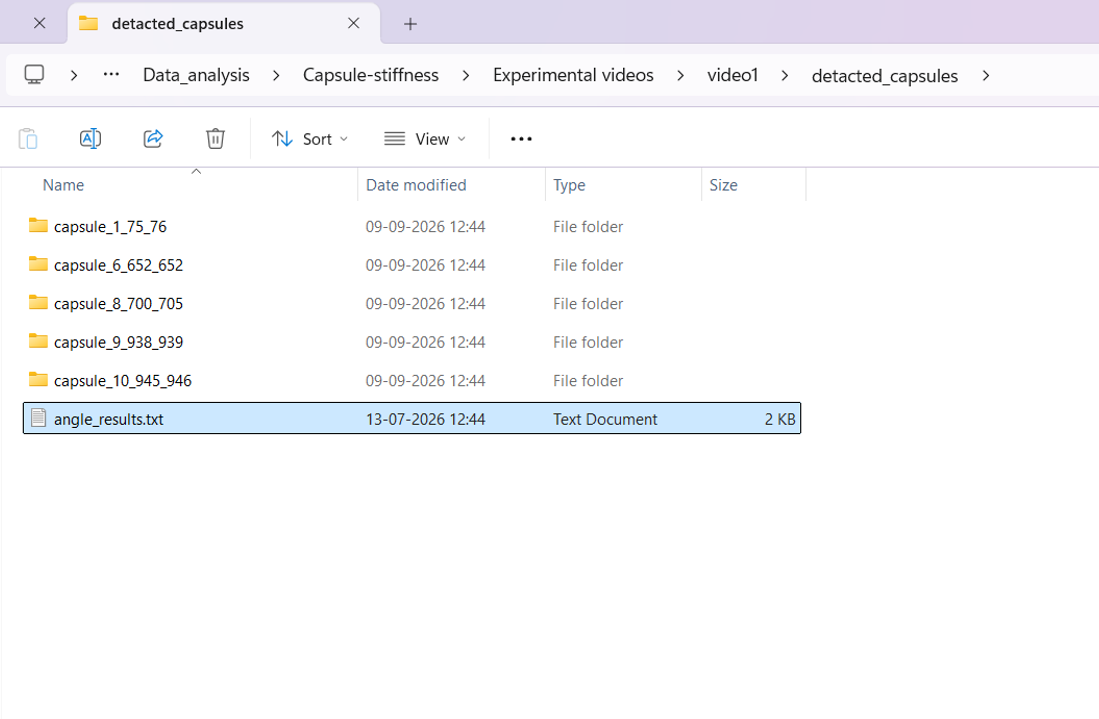

In [8]:
video_capture.release()
cv2.destroyAllWindows()
video_capture.release()


### Plot the angle distribution using Kernel Density Estimation (KDE)

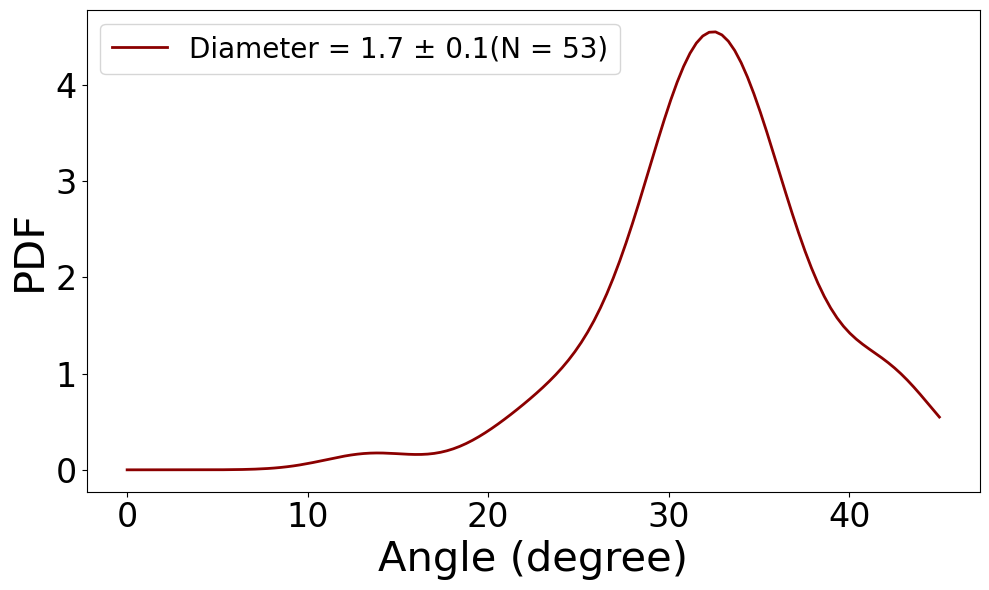

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

files = {

    "Day #": r"C:\Users\HP\Desktop\ICTP\Hands-on_Day#\capsules-distribution.txt",
}

# Angle range
theta = np.linspace(0, np.pi / 4, 128)
theta_deg = np.degrees(theta)

plt.figure(figsize=(10, 6))
for day, file in files.items():

    angles = np.loadtxt(
        file,
        skiprows=2,
        usecols=4
    )

    kde = gaussian_kde(angles)

    plt.plot(
        theta_deg,
        kde(theta),
        linewidth=2,
        label=f"Diameter = 1.7 ± 0.1(N = {len(angles)})",
        color = "darkred"
    )
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.legend(fontsize=20)
# plt.legend(prop={'size': 50})

plt.xlabel("Angle (degree)", fontsize = 30)
plt.ylabel("PDF", fontsize = 30)

# plt.legend()
plt.tight_layout()

plt.savefig(
    r"C:\Users\HP\Desktop\ICTP\Day6_angle_distribution.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()